# 05 · Un score « protéines de stockage » pour l'anaphylaxie alimentaire

Le notebook 04 a montré que l'information des IgE sur l'antécédent d'anaphylaxie alimentaire tient surtout dans le
nombre d'**albumines 2S** et de **légumines 11S** reconnues (protéines de stockage des graines : arachide, fruits à
coque, soja, sésame, sarrasin). On en fait un score qu'un clinicien peut lire directement sur un compte rendu de puce :

> **score = nombre d'allergènes positifs (≥ 0.3) parmi les 2S et 11S du panel commun aux trois puces**
> (2S : Ara h 2, Ara h 6, Ber e 1, Fag e 2, Jug r 1, Ses i 1 ; 11S : Ana o 2, Ara h 3, Cor a 9, Gly m 6).

On regarde trois choses : **le risque observé par niveau de score**, **le score comme test** (seuils, sensibilité,
spécificité, rapports de vraisemblance) et **la calibration** des risques prédits, dans la cohorte (CV 10 × 5) puis
d'une région à l'autre.

**En bref** :

1. Le score est un marqueur pour **confirmer** le risque, pas pour l'**écarter**. À partir de 2 protéines positives,
   98 % des patients ont un antécédent d'anaphylaxie (spécificité 0.99, LR+ ≈ 24) ; mais 52 % des patients à score 0
   en ont un aussi (lait, œuf, poisson, crustacés, LTP...) : sensibilité 0.30.
2. Ses risques sont **bien calibrés** dans la cohorte (pente 1.04, ECE 0.02), mieux que le gradient boosting du
   notebook 04 qui discrimine mieux mais est surconfiant (pente 0.73).
3. D'une région à l'autre, le risque à **score ≥ 2 reste entre 0.91 et 1.00 dans les 7 régions**, alors que le risque
   à score 0 varie de 0.29 à 0.71 avec la prévalence locale. La règle « ≥ 2 » se transporte, le bas de l'échelle doit
   être recalibré par centre.

**Limite principale** : le score a été suggéré par l'analyse de cette même cohorte. La validation croisée protège les
risques estimés, pas le choix du score ; le test par région est une validation externe partielle, une autre cohorte
serait la vraie. Calculs : `python -m acc.score` (job `acc/score` sur Chav), résultats dans `data/processed/runs/score`.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from acc.data import PROJECT_ROOT
from acc.score import corrected_ci, wilson

warnings.filterwarnings("ignore")
RUN = PROJECT_ROOT / "data" / "processed" / "runs" / "score"
FIG = PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
     "grid.alpha": 0.3, "grid.linewidth": 0.6, "figure.dpi": 110, "font.size": 9}
)
# first validated categorical slots; gray for the pooled cohort
CHIP_COLORS = {"all": "#52514e", "ALEX": "#2a78d6", "ISAC_V1": "#eb6834", "ISAC_V2": "#1baf7a"}

meta = json.loads((RUN / "meta.json").read_text())
risk = pd.read_csv(RUN / "risk_table.csv")
thr = pd.read_csv(RUN / "thresholds.csv")
folds = pd.read_csv(RUN / "folds.csv")
oof = pd.read_csv(RUN / "oof_repeat0.csv")
tr = pd.read_csv(RUN / "transport.csv")
print("score:", meta["components"][meta["primary"]])
print(f"{len(oof)} patients, prévalence de l'anaphylaxie : {oof.y.mean():.3f}")

score: ['Ara_h_2', 'Ara_h_6', 'Ber_e_1', 'Fag_e_2', 'Jug_r_1', 'Ses_i_1', 'Ana_o_2', 'Ara_h_3', 'Cor_a_9', 'Gly_m_6']
1699 patients, prévalence de l'anaphylaxie : 0.634


## 1. Risque observé par niveau de score

Proportion de patients avec un antécédent d'anaphylaxie alimentaire à chaque niveau (3 = 3 ou plus), IC de Wilson
à 95 %, pour la cohorte et pour chaque puce. La ligne pointillée est la prévalence globale.

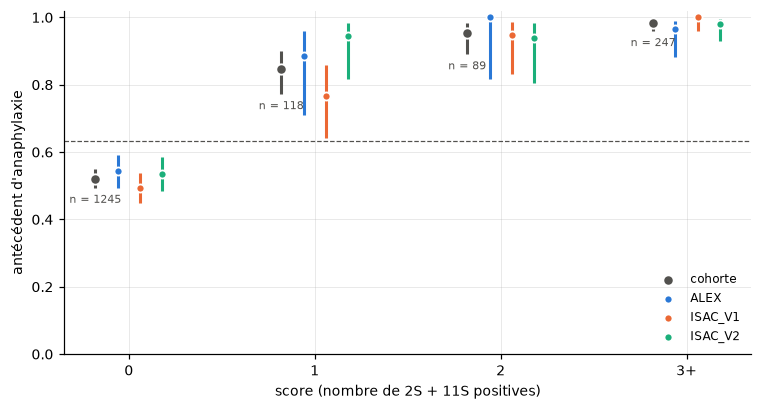

,chip,level,n,cases,risk,lo,hi
0,all,0,1245,649,0.521,0.494,0.549
1,all,1,118,100,0.847,0.772,0.901
2,all,2,89,85,0.955,0.890,0.982
3,all,3,247,243,0.984,0.959,0.994


In [2]:
fig, ax = plt.subplots(figsize=(7, 3.8))
groups = ["all", "ALEX", "ISAC_V1", "ISAC_V2"]
for j, g in enumerate(groups):
    r = risk[risk.chip == g]
    x = r.level + (j - 1.5) * 0.12
    ax.vlines(x, r.lo, r.hi, color=CHIP_COLORS[g], lw=2)
    ax.scatter(x, r.risk, s=(46 if g == "all" else 28), color=CHIP_COLORS[g], edgecolors="white",
               linewidths=1.2, zorder=3, label={"all": "cohorte"}.get(g, g))
ax.axhline(oof.y.mean(), color="#52514e", lw=0.8, ls="--")
ax.set_xticks(range(4), ["0", "1", "2", "3+"])
ax.set_xlabel("score (nombre de 2S + 11S positives)")
ax.set_ylabel("antécédent d'anaphylaxie")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=8, loc="lower right")
for _, r in risk[risk.chip == "all"].iterrows():
    ax.annotate(f"n = {r.n}", (r.level - 0.18, r.lo - 0.02), ha="center", va="top", fontsize=7, color="#52514e")
fig.tight_layout()
fig.savefig(FIG / "05_risk_by_score.png", dpi=200, bbox_inches="tight")
plt.show()
risk[risk.chip == "all"].round(3)

**Lecture.** Le risque passe de 0.52 à score 0 à 0.85 avec une protéine, 0.96 avec deux et 0.98 au-delà, avec la même
forme sur les trois puces (les échelles ISU et kUA/L sont lues au même seuil 0.3 et donnent des courbes très
proches). Les trois quarts des patients sont à score 0 : c'est là que se trouve toute l'incertitude.

## 2. Le score comme test : seuils

« Score ≥ k » utilisé comme test, avec IC bootstrap percentile (2 000 rééchantillonnages de patients). Quatre
variantes : 2S seules, 2S + 11S (**score principal**), toutes les protéines de stockage (+ 7S vicilines : Ara h 1,
Gly m 5), et une variante exploratoire qui ajoute la caséine du lait (Bos d 8) et l'ovomucoïde de l'œuf (Gal d 1).

In [3]:
show = thr[thr.metric.isin(["sensitivity", "specificity", "ppv", "npv", "lr_pos", "lr_neg"])].copy()
show["cell"] = show.apply(
    lambda r: f"{r.value:.2f} [{r.lo:.2f}, {r.hi:.2f}]" if np.isfinite(r.value) else "inf", axis=1
)
table = show.pivot_table(index=["score", "threshold"], columns="metric", values="cell", aggfunc="first")
table[["sensitivity", "specificity", "ppv", "npv", "lr_pos", "lr_neg"]]

metric                            sensitivity        specificity  \
score            threshold                                         
2S               1          0.34 [0.32, 0.37]  0.98 [0.97, 0.99]   
                 2          0.25 [0.23, 0.28]  0.99 [0.98, 1.00]   
                 3          0.11 [0.09, 0.13]  1.00 [1.00, 1.00]   
2S+11S           1          0.40 [0.37, 0.43]  0.96 [0.94, 0.97]   
                 2          0.30 [0.28, 0.33]  0.99 [0.98, 1.00]   
                 3          0.23 [0.20, 0.25]  0.99 [0.99, 1.00]   
storage          1          0.41 [0.38, 0.44]  0.95 [0.93, 0.97]   
                 2          0.33 [0.30, 0.36]  0.98 [0.97, 0.99]   
                 3          0.27 [0.24, 0.29]  0.99 [0.99, 1.00]   
storage+milk+egg 1          0.44 [0.41, 0.47]  0.94 [0.92, 0.96]   
                 2          0.35 [0.32, 0.38]  0.98 [0.96, 0.99]   
                 3          0.28 [0.25, 0.31]  0.99 [0.98, 1.00]   

metric                                    ppv                npv  \
score            threshold                                         
2S               1          0.97 [0.95, 0.99]  0.46 [0.44, 0.49]   
                 2          0.98 [0.96, 0.99]  0.43 [0.41, 0.46]   
                 3          1.00 [1.00, 1.00]  0.39 [0.37, 0.42]   
2S+11S           1          0.94 [0.92, 0.96]  0.48 [0.45, 0.51]   
                 2          0.98 [0.96, 0.99]  0.45 [0.42, 0.48]   
                 3          0.98 [0.97, 1.00]  0.43 [0.40, 0.45]   
storage          1          0.93 [0.91, 0.95]  0.48 [0.45, 0.51]   
                 2          0.97 [0.95, 0.99]  0.46 [0.43, 0.49]   
                 3          0.99 [0.97, 1.00]  0.44 [0.41, 0.47]   
storage+milk+egg 1          0.93 [0.91, 0.95]  0.49 [0.46, 0.52]   
                 2          0.96 [0.94, 0.98]  0.46 [0.44, 0.49]   
                 3          0.98 [0.96, 0.99]  0.44 [0.42, 0.47]   

metric                                     lr_pos             lr_neg  
score            threshold                                            
2S               1           19.43 [11.67, 44.50]  0.67 [0.64, 0.70]  
                 2           25.99 [13.70, 81.98]  0.76 [0.73, 0.78]  
                 3                            inf  0.89 [0.87, 0.91]  
2S+11S           1             9.51 [6.79, 15.18]  0.63 [0.60, 0.66]  
                 2           23.68 [13.41, 63.75]  0.70 [0.68, 0.73]  
                 3          35.08 [16.52, 142.21]  0.78 [0.75, 0.81]  
storage          1             7.90 [5.86, 11.87]  0.63 [0.59, 0.66]  
                 2           18.59 [11.38, 41.03]  0.68 [0.65, 0.71]  
                 3          41.29 [19.55, 167.97]  0.74 [0.71, 0.77]  
storage+milk+egg 1             7.82 [5.85, 11.36]  0.59 [0.56, 0.63]  
                 2            14.40 [9.41, 27.65]  0.67 [0.64, 0.70]  
                 3           24.92 [13.71, 83.40]  0.73 [0.70, 0.76]

**Lecture.**

- **Score ≥ 2** (score principal) : spécificité 0.99 [0.98, 1.00], VPP 0.98, **LR+ ≈ 24** [13, 64] ; sensibilité 0.30.
  Un LR+ au-dessus de 10 est conventionnellement « fort » : un score ≥ 2 fait passer une cote pré-test de 1 contre 1
  à environ 24 contre 1.
- **LR− ≈ 0.6–0.7** quel que soit le seuil : un score bas ne rassure presque pas. Le score ne sert pas à exclure.
- Ajouter les 11S aux 2S gagne de la sensibilité sans perdre de spécificité ; ajouter lait et œuf gagne encore un peu
  de sensibilité (0.44 à ≥ 1) au prix de la spécificité.
- VPP et VPN dépendent de la prévalence (0.63 ici, cohorte hospitalière) : elles ne se transposent pas telles
  quelles ; les LR, propriétés du test, se transposent mieux (voir aussi la section 4).

## 3. Calibration en validation croisée

Mêmes folds que le notebook 04 (5-fold stratifié × 10). Modèles :

- `score` : régression logistique sur les niveaux du score (catégoriels 0 / 1 / 2 / 3+, sans hypothèse de
  linéarité) + puce, pour chacune des 4 variantes ;
- `demo+score` : la même avec âge, région et puce ;
- références : `demo` (logistique) et `demo+pfam` (gradient boosting du notebook 04).

Calibration : **intercept** (« calibration in the large », 0 = bon niveau moyen) et **pente** (1 = ni surconfiant ni
sous-confiant ; < 1 = prédictions trop extrêmes) par recalibration logistique sur le fold de test, et ECE (erreur
absolue moyenne sur 10 bins). Intervalles corrigés de Nadeau-Bengio.

In [4]:
rows = []
for (m, s), g in folds.groupby(["model", "score"]):
    row = {"modèle": m, "score": s}
    for k in ["auc", "brier", "cal_intercept", "cal_slope", "ece"]:
        mean, lo, hi = corrected_ci(g[k], g.n_train.mean(), g.n_test.mean())
        row[k] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(row)
pd.DataFrame(rows).set_index(["modèle", "score"])

auc                 brier  \
modèle     score                                                          
demo       -                 0.720 [0.691, 0.748]  0.201 [0.193, 0.210]   
demo+pfam  -                 0.850 [0.831, 0.869]  0.153 [0.143, 0.164]   
demo+score 2S+11S            0.787 [0.763, 0.811]  0.178 [0.169, 0.188]   
score      2S                0.676 [0.656, 0.696]  0.199 [0.193, 0.205]   
           2S+11S            0.693 [0.671, 0.715]  0.196 [0.190, 0.202]   
           storage           0.690 [0.667, 0.713]  0.197 [0.190, 0.203]   
           storage+milk+egg  0.706 [0.683, 0.730]  0.193 [0.187, 0.200]   

                                      cal_intercept             cal_slope  \
modèle     score                                                            
demo       -                  0.001 [-0.063, 0.064]  0.970 [0.749, 1.191]   
demo+pfam  -                 -0.054 [-0.208, 0.099]  0.731 [0.627, 0.835]   
demo+score 2S+11S             0.000 [-0.087, 0.087]  0.972 [0.802, 1.143]   
score      2S                 0.000 [-0.059, 0.060]  1.134 [0.721, 1.546]   
           2S+11S            -0.000 [-0.066, 0.066]  1.039 [0.813, 1.265]   
           storage            0.000 [-0.065, 0.065]  1.048 [0.780, 1.316]   
           storage+milk+egg   0.000 [-0.072, 0.072]  1.028 [0.819, 1.237]   

                                              ece  
modèle     score                                   
demo       -                 0.053 [0.040, 0.067]  
demo+pfam  -                 0.066 [0.049, 0.084]  
demo+score 2S+11S            0.048 [0.035, 0.061]  
score      2S                0.014 [0.004, 0.024]  
           2S+11S            0.022 [0.012, 0.031]  
           storage           0.029 [0.019, 0.039]  
           storage+milk+egg  0.025 [0.015, 0.035]

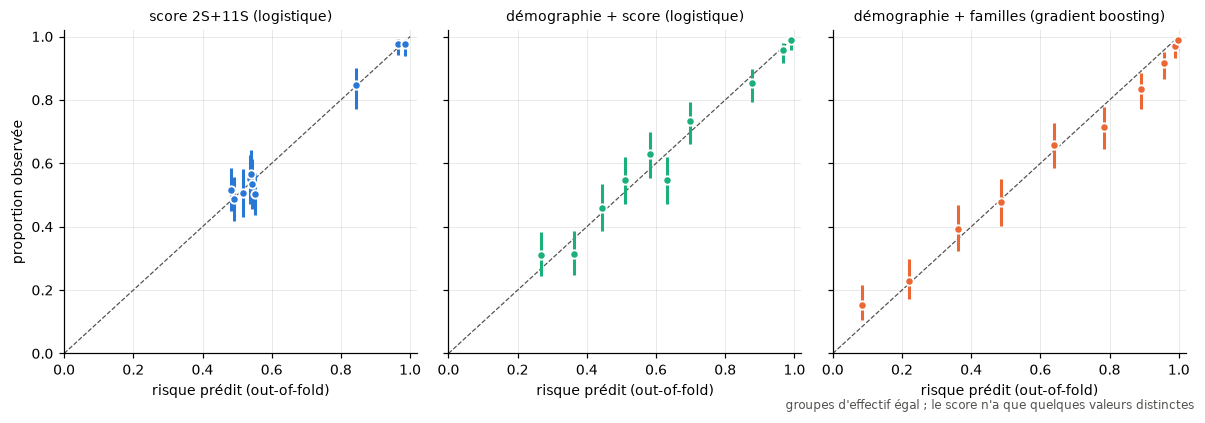

In [5]:
def reliability(p, y, bins=10):
    """Quantile bins: equal-count groups, so every point has a usable sample."""
    q = pd.qcut(p, bins, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": y, "b": q}).groupby("b", observed=True)
    out = g.agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size")).reset_index(drop=True)
    ci = [wilson(int(round(o * n)), n) for o, n in zip(out.obs, out.n)]
    out["lo"], out["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    return out


curves = {
    "score 2S+11S (logistique)": ("score|2S+11S", "#2a78d6"),
    "démographie + score (logistique)": ("demo+score|2S+11S", "#1baf7a"),
    "démographie + familles (gradient boosting)": ("demo+pfam|-", "#eb6834"),
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, (name, (col, color)) in zip(axes, curves.items()):
    r = reliability(oof[col].to_numpy(), oof.y.to_numpy())
    ax.plot([0, 1], [0, 1], color="#52514e", lw=0.8, ls="--")
    ax.vlines(r.pred, r.lo, r.hi, color=color, lw=2)
    ax.scatter(r.pred, r.obs, s=30, color=color, edgecolors="white", linewidths=1.2, zorder=3)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("risque prédit (out-of-fold)")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("proportion observée")
fig.text(0.99, 0.01, "groupes d'effectif égal ; le score n'a que quelques valeurs distinctes", ha="right",
         fontsize=8, color="#52514e")
fig.tight_layout()
fig.savefig(FIG / "05_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.**

- Le score seul : AUC 0.69 (limitée par la faible sensibilité : les trois quarts des patients ont la même valeur),
  mais **calibration excellente** (intercept 0.00, pente 1.04 [0.81, 1.27], ECE 0.02).
- Avec la démographie : AUC 0.79, toujours bien calibré (pente 0.97). Le score apporte +0.07 d'AUC à la démographie.
- Le gradient boosting `demo+pfam` reste le plus discriminant (+0.06 d'AUC sur `demo+score`) mais il est
  **surconfiant** : pente 0.73 [0.63, 0.84] par fold. Sur la courbe poolée l'écart reste modeste et se voit aux extrémités (risque prédit 0.08, observé 0.15 ; 0.96 prédit, 0.92 observé). Il faudrait le recalibrer
  (Platt, isotonique, dans la CV) avant de lire ses probabilités.

## 4. La calibration voyage-t-elle ? Leave-one-region-out

Le modèle `score` (niveaux + puce) est entraîné sur toutes les régions sauf une, puis évalué sur la région tenue à part.
On regarde aussi le risque observé dans la région à score 0 et à score ≥ 2, et ce que donnerait une **mise à jour de
l'intercept** par le centre (on recale le niveau moyen sur la prévalence locale ; ce calcul utilise les labels de la
région, c'est une borne haute de ce qu'une mise à jour locale apporterait).

In [6]:
view = tr[["region", "n_test", "prevalence", "mean_predicted", "auc", "cal_intercept", "cal_slope", "brier",
           "brier_intercept_updated", "n_0", "risk_0", "n_2plus", "risk_2plus"]]
view.round(3)

,region,n_test,prevalence,mean_predicted,auc,cal_intercept,cal_slope,brier,brier_intercept_updated,n_0,risk_0,n_2plus,risk_2plus
0,regionC,314,0.697,0.582,0.687,0.600,1.241,0.195,0.181,219,0.575,67,1.000
1,regionF,298,0.497,0.638,0.552,-0.654,0.546,0.257,0.237,254,0.425,33,0.909
2,regionA,213,0.394,0.679,0.684,-1.432,0.770,0.282,0.198,165,0.291,27,0.926
3,regionJ,195,0.733,0.625,0.666,0.599,0.976,0.187,0.171,135,0.630,49,0.980
4,regionL,184,0.837,0.710,0.724,0.914,1.071,0.143,0.119,94,0.702,72,1.000
5,regionM,171,0.532,0.644,0.613,-0.510,0.887,0.235,0.221,146,0.459,20,0.950
6,regionI,115,0.800,0.650,0.688,0.892,0.757,0.176,0.145,76,0.711,28,0.964


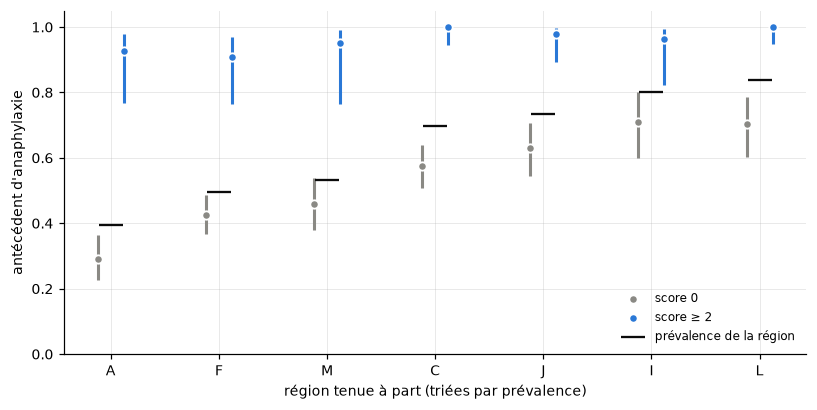

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
order = tr.sort_values("prevalence").region.tolist()
x = np.arange(len(order))
t = tr.set_index("region").loc[order]
for off, lvl, color, label in [(-0.12, "0", "#8a8984", "score 0"), (0.12, "2plus", "#2a78d6", "score ≥ 2")]:
    n = t[f"n_{lvl}"].to_numpy()
    k = np.round(t[f"risk_{lvl}"].to_numpy() * n).astype(int)
    ci = np.array([wilson(a, b) for a, b in zip(k, n)])
    ax.vlines(x + off, ci[:, 0], ci[:, 1], color=color, lw=2)
    ax.scatter(x + off, t[f"risk_{lvl}"], s=30, color=color, edgecolors="white", linewidths=1.2, zorder=3,
               label=label)
ax.scatter(x, t.prevalence, marker="_", s=260, color="#0b0b0b", lw=1.5, zorder=4, label="prévalence de la région")
ax.set_xticks(x, [r.removeprefix("region") for r in order])
ax.set_xlabel("région tenue à part (triées par prévalence)")
ax.set_ylabel("antécédent d'anaphylaxie")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "05_transport_by_region.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.**

- La prévalence de l'antécédent d'anaphylaxie varie du simple au double selon la région (0.39 à 0.84) : elle reflète
  le recrutement et le codage de chaque centre. Le modèle entraîné ailleurs se trompe donc de **niveau moyen**
  (intercept de −1.4 à +0.9) et ses risques absolus ne sont pas transposables tels quels.
- Mais le **haut de l'échelle est stable** : à score ≥ 2, le risque observé est entre 0.91 et 1.00 dans les 7 régions.
  Ce qui varie, c'est le risque à score 0 (0.29 à 0.71), qui suit la prévalence locale.
- Une simple mise à jour de l'intercept par le centre réduit le Brier dans toutes les régions (par exemple 0.28 → 0.20
  dans la région A).
- Le score 1 est le niveau le plus instable (0.52 à 1.00, sur 5 à 28 patients par région).

## 5. Conclusions

**Ce que les résultats montrent** : dans cette cohorte hospitalière, avoir **au moins deux albumines 2S ou légumines
11S positives** identifie avec une très grande spécificité (0.99, LR+ ≈ 24) les patients qui ont un antécédent
d'anaphylaxie alimentaire, et ce constat tient dans chaque puce et dans chaque région testée. Les risques du score
sont bien calibrés en validation croisée.

**Ce qu'ils suggèrent** : un usage en *rule-in* (« ce profil est celui d'un patient à risque d'anaphylaxie »), avec
un risque de base à recaler sur chaque centre ; pas d'usage en *rule-out*.

**Ce qu'ils ne montrent pas** :

- un risque **futur** : l'antécédent et les IgE sont observés au même moment, et un patient sensibilisé qui évite
  strictement l'aliment peut n'avoir jamais réagi ; on prédit un antécédent, pas une réaction à venir ;
- une performance en **population générale** ou en ville : les patients non anaphylactiques de la cohorte sont des
  patients hospitaliers (souvent respiratoires), ce qui gonfle probablement la spécificité ;
- l'indépendance vis-à-vis de l'**indication de la puce** : la puce a pu être prescrite justement après une réaction ;
- la validité du **choix** du score, suggéré par l'analyse de la même cohorte (seuls les risques sont protégés par la
  CV).

**Suites possibles** : valider sur une autre cohorte ; décliner par aliment (arachide : Ara h 2/6 ; fruits à coque :
Jug r 1, Cor a 9, Ana o 2...) en croisant avec la clinique par aliment, absente des données publiées ; recalibrer le
gradient boosting et comparer les courbes de décision (net benefit) du score et du modèle complet.